# s-batches and order release with forecast

Two extensions on the **Fidentis case** (`data/generator/fidentis.json`, [21](../math/21_instance-generator.md) §4a;
10 orders, 2 workers, one printer, one mill, one oven, default calendar):

1. **s-batches** ([08](../math/08_serial-batches.md)): manual steps such as data preparation, polishing, inspection,
   cleaning and blasting take a setup once per batch; the planner (rule, CP-SAT) groups operations of one step across
   orders, one worker, one share per batch.
2. **Order release with forecast** ([33](../math/33_order-release-interface.md)): nesting binds accepted orders at
   every nesting batch during the run; the norm (N5) holds orders back while the mill's planned work plus the forecast
   reserve exceeds a window of daily capacity.

The computing cells store their results as JSON in `notebooks/results/08/` and load them on the next run, so
only the plots are drawn again; they recompute when the Fidentis parameters change or with `RECOMPUTE = True`
(after a change of the planners, the DES or the release code). A full computation takes about 10 minutes.
Rebuild with `uv run python notebooks/build_08_s_batches_and_forecast.py`.

In [1]:
%matplotlib inline
import hashlib
import json
import os
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

from simulation.calendar import day_index, day_start
from simulation.carrier_generator import CarrierGeneratorParams, generate_carrier_instance
from simulation.check.feasibility import check_schedule, worker_intervals
from simulation.control.nesting import average_daily_capacity, default_order_load
from simulation.io.json_loader import read_model
from simulation.metrics import plan_metrics
from simulation.model.compiled import compile_instance
from simulation.model.schedule import Schedule
from simulation.objectives import MAKESPAN
from simulation.planners.cpsat import solve
from simulation.planners.dispatching import dispatch_plan, ect, spt
from simulation.viz import plot_days

from forecast_episode import episode

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIDENTIS = read_model(ROOT / "data/generator/fidentis.json", CarrierGeneratorParams)
RESULTS = ROOT / "notebooks/results/08"
RECOMPUTE = False  # True: compute everything again (after a change of planners, DES or release code)
DIGEST = hashlib.sha256(FIDENTIS.model_dump_json().encode()).hexdigest()[:12]


def cached(name, compute):
    # compute() as JSON in RESULTS/<name>.json: loaded if stored for the same Fidentis parameters, else computed
    path = RESULTS / f"{name}.json"
    if not RECOMPUTE and path.exists() and (data := json.loads(path.read_text(encoding="utf-8")))["digest"] == DIGEST:
        print(f"loaded {path.relative_to(ROOT)}")
        return data["value"]
    value = compute()
    RESULTS.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"digest": DIGEST, "value": value}, indent=1) + "\n", encoding="utf-8")
    return value

## 1. s-batches on the Fidentis case

The s-batch steps of the case and their setup (inside each operation's duration, [08](../math/08_serial-batches.md)
§2); `clean` and `blast` take at most 4 plates per batch. The comparison instance is the same case without
`s_batch_steps`: every operation pays its setup.

In [2]:
for step, sb in FIDENTIS.s_batch_steps.items():
    print(f"{step:16} setup {sb.setup:3}" + (f", at most {sb.capacity} plates" if sb.capacity else ""))

support_removal  setup  15
grind            setup  10
steam            setup  10
polish_sec       setup  10
data_prep_pri    setup  15
polish_pri       setup  10
finish_pri       setup  10
inspect          setup  10
document         setup  10
pack             setup  10
clean            setup  15, at most 4 plates
blast            setup   5, at most 4 plates


Per variant the rule (SPT + ECT) and CP-SAT (makespan, hinted with the rule plan and its batches, the horizon
capped at the rule plan's end, math/12; 60 s on all cores; with several threads the result depends on the machine
and its load, the stored result is the one shown). Overtime per worker (A/B) are the minutes after shift end,
summed over the days. Worker minutes are the attended time of all shares; saved setup minutes are
$\sum_j (|O_j| - 1)\,p^{\mathrm{su}}_s$ over the batches of the plan.

In [3]:
def batch_stats(ci, plan):
    batches = {}
    for a in plan:
        if a.batch:
            batches.setdefault(a.batch, []).append(ci.op_index[a.order_id, a.op_id])
    saved = sum((len(ops) - 1) * ci.s_setup[ops[0]] for ops in batches.values())
    return len(batches), sum(map(len, batches.values())), saved


def worker_minutes(ci, plan):
    by_op = {ci.op_index[a.order_id, a.op_id]: a for a in plan}
    return sum(e - s for ivs in worker_intervals(ci, by_op).values() for s, e, _ in ivs)


def overtime_by_worker(ci, plan):  # minutes after shift end per worker, summed over the days (as plan_metrics)
    cal, by_op, last = ci.calendar, {ci.op_index[a.order_id, a.op_id]: a for a in plan}, {}
    for w, ivs in worker_intervals(ci, by_op).items():
        for s, e, _ in ivs:
            last[w, day_index(cal, s)] = max(last.get((w, day_index(cal, s)), 0), e)
    return "/".join(str(sum(max(0, e - day_start(cal, d) - cal.shift_end) for (v, d), e in last.items() if v == w))
                    for w in ci.worker_ids)


def compare():
    rows, plans = [], {}
    for variant, params in (("without", FIDENTIS.model_copy(update={"s_batch_steps": {}})), ("with", FIDENTIS)):
        ci = compile_instance(generate_carrier_instance(params))
        rule = dispatch_plan(ci, spt, ect)
        cp = solve(ci, MAKESPAN, time_limit=60, workers=os.cpu_count(), hint=rule.assignments)
        for planner, plan, breaks in (("rule", rule.assignments, rule.breaks), ("cpsat", cp.schedule, cp.breaks)):
            assert check_schedule(ci, plan, breaks=breaks) == []
            m = plan_metrics(ci, plan)
            n, members, saved = batch_stats(ci, plan)
            solver = f"{cp.status} bound {cp.bound}" if planner == "cpsat" else ""
            rows.append((variant, planner, max(a.end for a in plan), m["tardy_days"], m["overtime"],
                         overtime_by_worker(ci, plan), worker_minutes(ci, plan), n, members, saved, solver))
            plans[f"{variant}/{planner}"] = Schedule(assignments=plan, breaks=breaks).model_dump(mode="json")
    return {"rows": rows, "plans": plans}


S_BATCHES = cached("s_batches", compare)
print(f"{'s-batches':9} {'planner':7} {'makespan':>8} {'tardy d':>7} {'overtime':>8} {'A/B':>9} {'worker min':>10} "
      f"{'batches':>7} {'members':>7} {'saved':>5}  CP-SAT")
for r in S_BATCHES["rows"]:
    print(f"{r[0]:9} {r[1]:7} {r[2]:8} {r[3]:7} {r[4]:8} {r[5]:>9} {r[6]:10} {r[7]:7} {r[8]:7} {r[9]:5}  {r[10]}")

loaded notebooks\results\08\s_batches.json
s-batches planner makespan tardy d overtime       A/B worker min batches members saved  CP-SAT
without   rule       30790       0        0       0/0       8830       0       0     0  
without   cpsat      23080       0      762   447/315       8830       0       0     0  FEASIBLE bound 14355
with      rule       30730       0        0       0/0       8155      38      99   675  
with      cpsat      24500       0      916   543/373       8365      25      68   465  FEASIBLE bound 13816


The first working days of the rule plan with s-batches, per worker: one bar per batch, labelled with all
its orders (e.g. `O3+O5 inspect`).

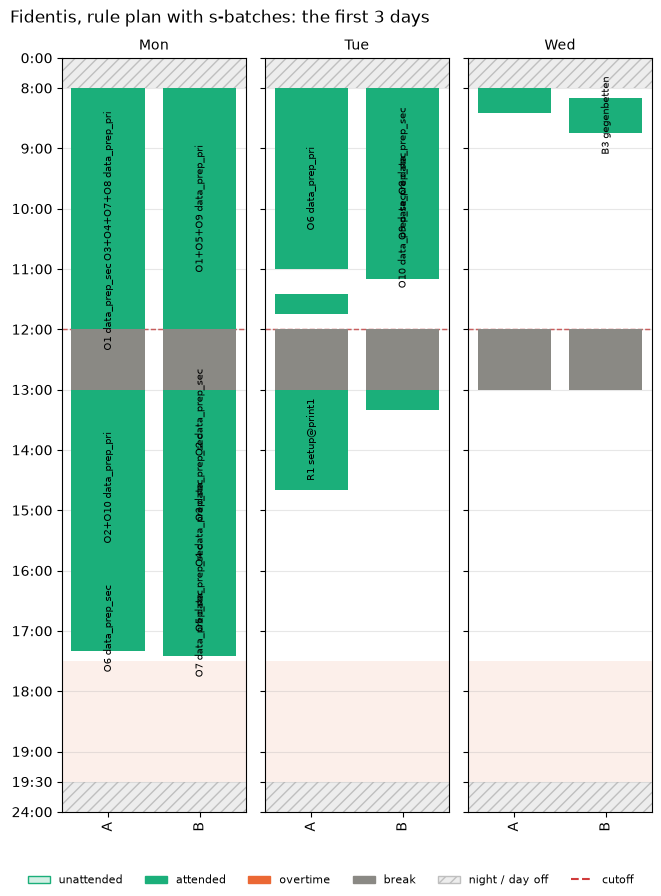

In [4]:
ci = compile_instance(generate_carrier_instance(FIDENTIS))
rule = Schedule.model_validate(S_BATCHES["plans"]["with/rule"])
plot_days(ci, rule.assignments, rule.breaks, days=3, rows="workers",
          title="Fidentis, rule plan with s-batches: the first 3 days")
plt.show()

## 2. Order release with forecast

Orders are accepted on working days (Poisson rate per day), nesting binds them at the daily nesting batch
(12:00), and the planning tool replans with the rule at every nesting time and repairs otherwise; disturbed
durations and start offsets (keyed scenario, [22](../math/22_scenarios.md)). **Bind all**: every accepted order is
bound at the next nesting batch. **Norm** (N5): an order is bound only while the mill's work in the plan plus the
forecast reserve stays within a window of $n^{\mathrm{win}}$ days of capacity (2, 3 or 5 days); the forecast
is the expected number of orders per nesting day, here the arrival rate; an order due before the next nesting batch
is always bound.
The capacity signal comes from the plan and the snapshot (math/33 §5).

In [5]:
MILL = ("mill1",)
BASE = FIDENTIS.model_copy(update={"release_range": (0, 0)})
load, longest = default_order_load(BASE, MILL)
capacity = average_daily_capacity(BASE.calendar, longest, len(MILL))
print(f"a default order (4 telescopes) needs {load} minutes on the mill (longest operation {longest}); the mill "
      f"gives {capacity:.0f} minutes a working day, {capacity / load:.2f} default orders")
RATES, WINDOWS, SEEDS = (0.6, 1.0), (2, 3, 5), (1, 2)


def norm(window, rate):  # the forecast is the arrival rate (expected orders per nesting day)
    return {"machines": MILL, "capacity_per_day": capacity, "window_days": window, "default_load": load,
            "forecast": dict.fromkeys(range(5), rate)}


def all_episodes():  # in parallel processes (forecast_episode.py next to the notebook)
    runs = [(rate, w, seed) for rate in RATES for w in (None, *WINDOWS) for seed in SEEDS]
    with ProcessPoolExecutor() as pool:
        return list(pool.map(episode, *zip(*((BASE, seed, rate, w and norm(w, rate)) for rate, w, seed in runs),
                                           strict=True)))


EPISODES = cached("forecast", all_episodes)
print(f"{'rate':>4} {'release':8} {'seed':>4} {'orders':>6} {'makespan':>8} {'tardy':>5} {'tardy d':>7} "
      f"{'overtime':>8} {'pool mean':>9} {'pool max':>8}")
for e in EPISODES:
    m, waits = e["metrics"], [arr - acc for acc, arr in e["pool"]]
    print(f"{e['rate']:4} {e['release']:8} {e['seed']:4} {len(waits):6} {m['makespan']:8} {m['tardy_orders']:5} "
          f"{m['tardy_days']:7} {m['overtime']:8} {mean(waits):9.0f} {max(waits):8}")

a default order (4 telescopes) needs 1268 minutes on the mill (longest operation 280); the mill gives 970 minutes a working day, 0.76 default orders
loaded notebooks\results\08\forecast.json
rate release  seed orders makespan tardy tardy d overtime pool mean pool max
 0.6 bind all    1      4    16391     1       2        4        61      128
 0.6 bind all    2      7    31738     2      15        6       267     1323
 0.6 norm 2 d    1      4    16391     1       1        4       781     3008
 0.6 norm 2 d    2      7    35032     3       6       14      6233    12843
 0.6 norm 3 d    1      4    16391     1       1        4       781     3008
 0.6 norm 3 d    2      7    32212     4       6      183      4793     9963
 0.6 norm 5 d    1      4    16391     1       2        4        61      128
 0.6 norm 5 d    2      7    32152     3       8       26      1913     8523
 1.0 bind all    1      8    32241     4      22      198       683     1330
 1.0 bind all    2     11    51916     

Pool time per order (from acceptance to binding) for seed 1: with the norm the orders wait in the pool
instead of in the shop.

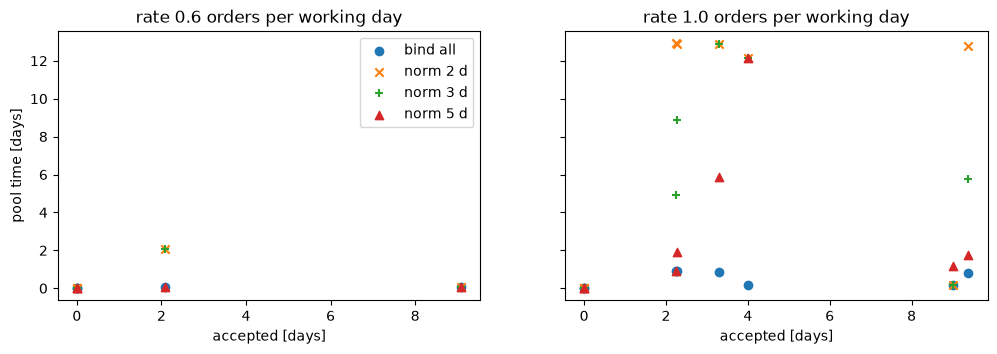

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, rate in zip(axes, (0.6, 1.0), strict=True):
    for release, marker in (("bind all", "o"), *((f"norm {w} d", m) for w, m in zip(WINDOWS, "x+^", strict=True))):
        pool = next(e["pool"] for e in EPISODES if (e["rate"], e["release"], e["seed"]) == (rate, release, 1))
        ax.scatter([a / 1440 for a, _ in pool], [(b - a) / 1440 for a, b in pool], marker=marker, label=release)
    ax.set_title(f"rate {rate} orders per working day")
    ax.set_xlabel("accepted [days]")
axes[0].set_ylabel("pool time [days]")
axes[0].legend()
plt.show()

## Findings (run of 2026-11-19)

**s-batches.** The rule forms 38 batches with 99 operations and saves 675 setup minutes; worker time drops from 8830
to 8155 minutes (−8 %). The makespan hardly moves (30790 → 30730): the single mill is the bottleneck (about 1268
minutes per order), and s-batches save worker time, not mill time. The rule plans no overtime; CP-SAT uses some
(762 and 916 minutes over both workers) for a shorter makespan, since the objective is makespan only. CP-SAT (60 s,
12 threads, horizon capped at the rule plan's end, the rule's batches hinted) still gets *worse* with s-batches
(23080 → 24500) and keeps fewer batches than the rule (25 against 38): the slots (106 s-batch operations, 562 slot
literals) enlarge the model more than the batches help. The cap and the hint changed little (24700 → 24500). Both
bounds (about 14000) are close to the mill's pure processing time (13732 minutes); 180 s on 12 threads (outside the
notebook) gave 23060 and 23200 with the same bounds, so the gap is mostly the bound, which does not see that the
mill's attended setups and removals wait for the shift.

**Order release with forecast.** The forecast is now the arrival rate, the window 2, 3 or 5 days. Below capacity
(rate 0.6, 0.79 of the mill) the norm cuts the tardy days of seed 2 from 15 to 6–8, but more orders are tardy (2
→ 3–4) and the orders wait in the pool (mean 1913–6233 minutes); seed 1 (4 orders) hardly changes. Above capacity
(rate 1.0) a 2-day window is worse than binding all (41 and 72 against 22 and 75 tardy days), 3 and 5 days are
mixed (20 and 63, 33 and 53). Two seeds and short episodes (4 to 11 orders) are too few to conclude; what they show:
the norm moves waiting from the shop to the pool and does not by itself reduce tardiness. The rate sweep and the
experiment configurations follow ([33](../math/33_order-release-interface.md)).